<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 4 — Statistical Tests in Python</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

#### Worked examples: comparing two groups, checking assumptions, the size of a difference, and correlation.
***

## Why this notebook

The statistical tests of Lecture 5 and the Week 4 lab, in Python: how to run them, what they tell you, and how to choose. Each section has a worked example, then a short *Your turn*; Section 7 has optional practice with numbers to check against. About 20 minutes; a worked copy with every answer is next to this notebook.

The data are made up, so that we know the right answer. Nothing here is assessed, and it adds no new requirements to Exercise 2: it shows the tools, and the choices are still yours.

1. comparing two groups: Welch's t-test and the Mann–Whitney rank test;
2. when the two disagree: skewed data and an outlier;
3. checking the assumptions by looking;
4. how big is the difference? An interval from the bootstrap, and the Hodges–Lehmann estimate;
5. many quantities at once: a results table with pandas;
6. correlation: Pearson and Spearman;
7. optional practice.

If arrays, loops or functions feel shaky, the [Python foundations notebook](https://colab.research.google.com/github/MatSmithAstro/phys7101_2026_resources/blob/main/workshops/python_foundations/python_foundations.ipynb) practises them first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(7)

## <span style="color:#B5121B">1. Comparing two groups</span>

Two groups of 15 people; we measure one quantity in each. The **null hypothesis** of both tests is "no difference between the groups"; the p-value is the probability of a difference at least as large as the one seen *if the null hypothesis were true*. It is not the probability that the null hypothesis is true.

- **Welch's t-test** (`stats.ttest_ind(a, b, equal_var=False)`) compares the *means*. It assumes each group's mean is roughly Gaussian, which holds for near-Gaussian data, or for skewed data once the groups are large. `equal_var=False` (Welch) does not assume the two groups have the same spread: use it by default.
- **The Mann–Whitney test** (`stats.mannwhitneyu(a, b)`) uses only the *ranks*: is a randomly chosen value from one group likely to be larger than one from the other? It makes no assumption about the shape of the distribution, so a few extreme values cannot dominate it.

In [2]:
a = rng.normal(60, 8, 15)        # group A: mean 60, spread 8
b = rng.normal(70, 8, 15)        # group B: mean 70, the same spread
t = stats.ttest_ind(a, b, equal_var=False)
u = stats.mannwhitneyu(a, b)
print(f"means {a.mean():.1f} and {b.mean():.1f}")
print(f"Welch t-test:  t = {t.statistic:.2f}, p = {t.pvalue:.3f}")
print(f"Mann-Whitney:  U = {u.statistic:.0f}, p = {u.pvalue:.3f}")

means 58.9 and 64.5
Welch t-test:  t = -2.37, p = 0.026
Mann-Whitney:  U = 66, p = 0.056


For near-Gaussian data the two tests usually give similar answers: here p ≈ 0.03 and 0.06, both pointing to a difference, though with 15 people per group neither is overwhelming (and 0.05 is a convention, not a cliff). Rerun with groups of 5 instead of 15: the same true difference is now often missed. A large p-value means *no evidence of a difference*, not *no difference*.

In [3]:
r_power = np.random.default_rng(11)          # a separate generator, so later sections are unchanged
for n in (5, 15):
    hits = np.mean([stats.ttest_ind(r_power.normal(60, 8, n), r_power.normal(70, 8, n), equal_var=False).pvalue < 0.05 for _ in range(2000)])
    print(f"groups of {n:2d}: the difference is detected in {hits:.0%} of experiments")

groups of  5: the difference is detected in 38% of experiments


groups of 15: the difference is detected in 90% of experiments


**Check:** about 40% with groups of 5 and about 90% with groups of 15: small groups miss real differences more often than they find them.

## <span style="color:#B5121B">2. When the two tests disagree</span>

Now the same comparison on skewed data (many small values, a few large ones, like many physiological quantities), plus one outlier in group A.

In [4]:
a2 = rng.lognormal(np.log(30), 0.6, 15)
b2 = rng.lognormal(np.log(45), 0.6, 15)
a2_out = np.append(a2, 400.0)                       # one extreme value added to A
for label, x in [("skewed", a2), ("skewed + outlier", a2_out)]:
    t = stats.ttest_ind(x, b2, equal_var=False); u = stats.mannwhitneyu(x, b2)
    print(f"{label:17s} mean A {x.mean():6.1f}, median A {np.median(x):5.1f}  |  Welch p = {t.pvalue:.3f}, Mann-Whitney p = {u.pvalue:.3f}")

skewed            mean A   30.1, median A  28.1  |  Welch p = 0.009, Mann-Whitney p = 0.008
skewed + outlier  mean A   53.2, median A  28.7  |  Welch p = 0.829, Mann-Whitney p = 0.026


One value moves group A's mean a long way and the t-test with it; the ranks barely change, so Mann–Whitney hardly moves. Neither test is "right" in general: the question is which one's assumptions your data meet, and whether a single value should be allowed to decide the answer. Say which you trust, and why.

In [5]:
b2_out = np.append(b2, 400.0)
print(f"Welch p = {stats.ttest_ind(a2, b2_out, equal_var=False).pvalue:.3f}, Mann-Whitney p = {stats.mannwhitneyu(a2, b2_out).pvalue:.3f}")
# Mann-Whitney barely changes (one more large value in B, which was already larger); Welch changes because
# the outlier inflates B's spread, so the same difference in means counts for less.

Welch p = 0.048, Mann-Whitney p = 0.005


## <span style="color:#B5121B">3. Check the assumptions by looking</span>

A histogram shows skewness and outliers; a **Q–Q plot** compares the data with a Gaussian: Gaussian data lie close to a straight line, skewed data curve away from it. With 15 values, a formal normality test (such as `stats.shapiro`) has little power, so look rather than rely on its p-value.

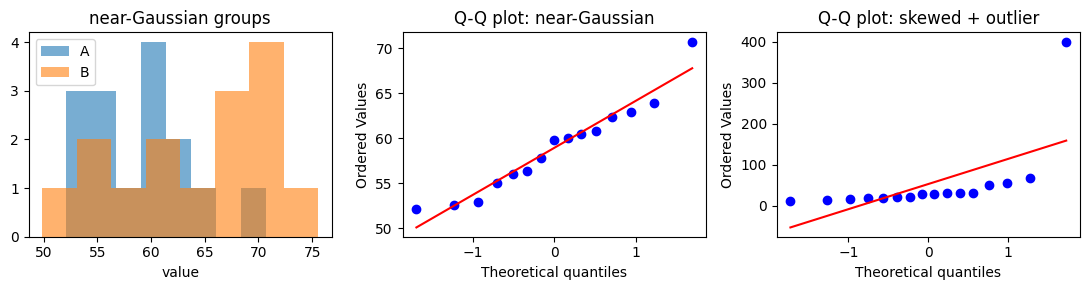

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(a, bins=8, alpha=0.6, label="A"); ax[0].hist(b, bins=8, alpha=0.6, label="B")
ax[0].set(title="near-Gaussian groups", xlabel="value"); ax[0].legend()
stats.probplot(a, plot=ax[1]); ax[1].set_title("Q-Q plot: near-Gaussian")
stats.probplot(a2_out, plot=ax[2]); ax[2].set_title("Q-Q plot: skewed + outlier")
plt.tight_layout(); plt.show()

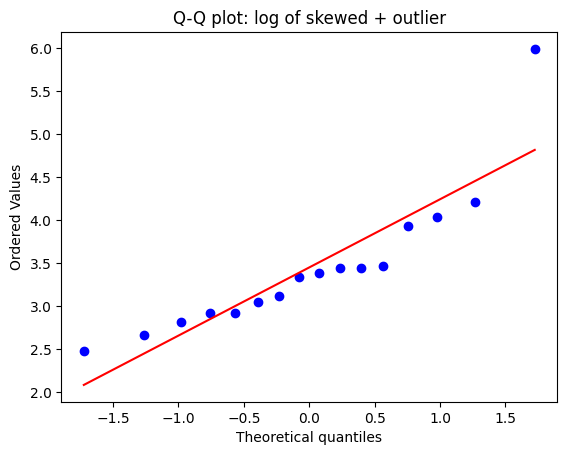

In [7]:
stats.probplot(np.log(a2_out), plot=plt.gca()); plt.title("Q-Q plot: log of skewed + outlier"); plt.show()
# The skewed values become close to a straight line; the outlier is still off it. On logged values a t-test is
# reasonable for the bulk, but one point can still dominate: the rank test is the safer choice here.

## <span style="color:#B5121B">4. How big is the difference?</span>

A p-value says whether there is evidence of a difference, not how big it is. Report the size, with an interval.

**The bootstrap** (Lecture 5): draw each group again, with replacement, at its own size; recompute the difference; repeat many times; the middle 95% of the results is the interval. Resample the **independent units** (here, people), never values that depend on each other.

**The Hodges–Lehmann estimate** (Lecture 8): the median of all the pairwise differences between the groups. It is the size estimate that goes with the Mann–Whitney test, robust to outliers in the same way.

In [8]:
def boot_interval(x, y, stat, n_boot=10000, seed=0):
    """95% bootstrap interval for stat(x, y), resampling each group separately."""
    r = np.random.default_rng(seed)
    vals = [stat(r.choice(x, len(x)), r.choice(y, len(y))) for _ in range(n_boot)]
    return np.percentile(vals, [2.5, 97.5])

diff_means = lambda x, y: y.mean() - x.mean()
hodges_lehmann = lambda x, y: np.median(np.subtract.outer(y, x))   # all pairwise differences

for label, x, y in [("near-Gaussian", a, b), ("skewed + outlier", a2_out, b2)]:
    lo, hi = boot_interval(x, y, diff_means)
    lo2, hi2 = boot_interval(x, y, hodges_lehmann)
    print(f"{label:17s} difference of means {diff_means(x, y):6.1f} (95%: {lo:6.1f} to {hi:6.1f});"
          f"  Hodges-Lehmann {hodges_lehmann(x, y):5.1f} ({lo2:5.1f} to {hi2:5.1f})")

near-Gaussian     difference of means    5.5 (95%:    1.0 to    9.8);  Hodges-Lehmann   6.7 (  0.1 to  11.1)


skewed + outlier  difference of means    5.5 (95%:  -48.4 to   43.2);  Hodges-Lehmann  19.0 (  3.4 to  41.8)


For the near-Gaussian groups the two estimates agree. With the outlier, the difference of means and its interval are pulled about; Hodges–Lehmann is not. Whichever you quote, say which it is.

In [9]:
diff_medians = lambda x, y: np.median(y) - np.median(x)
print(diff_medians(a2_out, b2), boot_interval(a2_out, b2, diff_medians))

19.60297780947556 [ 4.03029626 46.65403419]


## <span style="color:#B5121B">5. Many quantities at once</span>

With a table of one row per person and a column for each quantity, a loop gives a results table: one row per quantity. Write the comparison once, as a function.

In [10]:
people = pd.DataFrame({
    "group":   ["A"] * 15 + ["B"] * 15,
    "speed":   np.concatenate([a, b]),
    "reaction": np.concatenate([rng.normal(250, 30, 15), rng.normal(255, 30, 15)]),
    "skewed":  np.concatenate([a2, b2]),
})

def compare(df, column, g1="A", g2="B"):
    x = df.loc[df.group == g1, column].to_numpy(); y = df.loc[df.group == g2, column].to_numpy()
    lo, hi = boot_interval(x, y, hodges_lehmann, n_boot=4000)
    return {"quantity": column, "median A": np.median(x), "median B": np.median(y),
            "Hodges-Lehmann": hodges_lehmann(x, y), "95% low": lo, "95% high": hi,
            "Welch p": stats.ttest_ind(x, y, equal_var=False).pvalue,
            "Mann-Whitney p": stats.mannwhitneyu(x, y).pvalue}

results = pd.DataFrame([compare(people, c) for c in ["speed", "reaction", "skewed"]])
print(results.round(3).to_string(index=False))

quantity  median A  median B  Hodges-Lehmann  95% low  95% high  Welch p  Mann-Whitney p
   speed    59.766    66.339           6.690    0.090    11.140    0.026           0.056
reaction   244.114   249.081          11.284   -7.013    31.299    0.185           0.229
  skewed    28.055    48.341          23.503    8.779    43.959    0.009           0.008


`reaction` was drawn with almost no difference between the groups: its interval includes zero and both p-values are large. When you test several quantities, think about what that does to your chance of a false alarm (Lecture 5).

In [11]:
def compare_n(df, column, g1="A", g2="B"):
    out = compare(df, column, g1, g2)
    out["n A, n B"] = f"{(df.group == g1).sum()}, {(df.group == g2).sum()}"
    return out
print(pd.DataFrame([compare_n(people, c) for c in ["speed", "reaction", "skewed"]]).round(3).to_string(index=False))

quantity  median A  median B  Hodges-Lehmann  95% low  95% high  Welch p  Mann-Whitney p n A, n B
   speed    59.766    66.339           6.690    0.090    11.140    0.026           0.056   15, 15
reaction   244.114   249.081          11.284   -7.013    31.299    0.185           0.229   15, 15
  skewed    28.055    48.341          23.503    8.779    43.959    0.009           0.008   15, 15


## <span style="color:#B5121B">6. Correlation: Pearson and Spearman</span>

`stats.pearsonr(x, y)` measures a *linear* relationship; `stats.spearmanr(x, y)` uses ranks, so it measures any *monotonic* relationship and is robust to outliers (Lecture 7). Both return the coefficient and a p-value for "no correlation". Neither says which quantity causes the other, or whether a third causes both.

In [12]:
x = rng.uniform(0, 10, 40)
y_lin = 2 * x + rng.normal(0, 3, 40)
y_curve = np.exp(0.4 * x) + rng.normal(0, 2, 40)
for label, y in [("linear", y_lin), ("curved (monotonic)", y_curve)]:
    p = stats.pearsonr(x, y); s = stats.spearmanr(x, y)
    print(f"{label:19s} Pearson r = {p.statistic:.2f} (p = {p.pvalue:.1e});  Spearman rho = {s.statistic:.2f} (p = {s.pvalue:.1e})")
print("bootstrap 95% interval for Spearman (resampling pairs):",
      np.percentile([stats.spearmanr(*np.array([(x[i], y_curve[i]) for i in rng.integers(0, 40, 40)]).T).statistic for _ in range(2000)], [2.5, 97.5]).round(2))

linear              Pearson r = 0.91 (p = 1.6e-16);  Spearman rho = 0.91 (p = 2.1e-16)
curved (monotonic)  Pearson r = 0.89 (p = 8.8e-15);  Spearman rho = 0.96 (p = 4.8e-23)


bootstrap 95% interval for Spearman (resampling pairs): [0.89 0.99]


In [13]:
xo, yo = np.append(x, 9.5), np.append(y_lin, -40.0)
print(f"Pearson r = {stats.pearsonr(xo, yo).statistic:.2f}, Spearman rho = {stats.spearmanr(xo, yo).statistic:.2f}")
# Pearson drops a lot: it uses the values, and one far-off point carries a large weight. Spearman uses ranks,
# so the outlier is just one slightly misplaced rank.

Pearson r = 0.39, Spearman rho = 0.78


## <span style="color:#FD9029">7. Optional practice</span>

Three short problems. Check your numbers against the **Check** lines.

**P1. Paired or independent?** The same 12 people are measured before and after a change: `before = rng.normal(70, 10, 12)` and `after = before + rng.normal(2, 2, 12)`. Compare them with `stats.ttest_ind` (treating the groups as independent) and with `stats.ttest_rel` (the paired test). Why are the p-values so different? Use `np.random.default_rng(1)`.

In [14]:
r1 = np.random.default_rng(1)
before = r1.normal(70, 10, 12); after = before + r1.normal(2, 2, 12)
print(f"independent: p = {stats.ttest_ind(before, after, equal_var=False).pvalue:.3f};  paired: p = {stats.ttest_rel(before, after).pvalue:.4f}")
# The person-to-person spread (10) swamps a change of 2 when the groups are treated as independent; pairing
# compares each person with themselves, so only the spread of the changes (2) matters.

independent: p = 0.431;  paired: p = 0.0003


**Check:** the independent test finds nothing (p ≈ 0.4); the paired test finds the change easily (p < 0.01). Use a paired test only when each value in one group belongs with one in the other.

**P2. One-sided or two-sided?** `stats.mannwhitneyu(a, b, alternative="less")` asks only "is A smaller than B?". For the groups `a` and `b` of Section 1, compare the one-sided and two-sided p-values. When is a one-sided test justified?

In [15]:
print(stats.mannwhitneyu(a, b, alternative="less").pvalue, stats.mannwhitneyu(a, b).pvalue)
# The one-sided p-value is half the two-sided one. It is justified only if you decided the direction
# *before* looking at the data, for a physical reason; choosing it afterwards halves p for free.

0.028196182113415798 0.056392364226831596


**Check:** the one-sided p-value is half the two-sided one (here about 0.03 against 0.06).

**P3. How fast does an interval shrink?** Draw two Gaussian groups (means 60 and 70, spread 8) of size n = 10, 40 and 160, and find the width of the 95% bootstrap interval for the difference of means each time. How does the width scale with n?

In [16]:
r3 = np.random.default_rng(3)
for n in (10, 40, 160):
    lo, hi = boot_interval(r3.normal(60, 8, n), r3.normal(70, 8, n), diff_means, n_boot=4000)
    print(f"n = {n:3d}: width {hi - lo:.1f}")

n =  10: width 17.3
n =  40: width 7.1
n = 160: width 3.4


**Check:** the width roughly halves each time n is multiplied by 4 (about 17, 7 and 3.5): it scales as $1/\sqrt{n}$, so four times the data buys only twice the precision.

## Summary

- **Two groups:** Welch's t-test compares means and assumes near-Gaussian means; Mann–Whitney uses ranks and makes no assumption about shape. Look at the data (histogram, Q–Q plot) to choose, and say why.
- **p-values:** evidence against "no difference", not the probability that there is none; a large p-value with small groups is "no evidence", not "no effect".
- **Size:** always report how big the difference is, with an interval: the bootstrap (resampling independent units) for any statistic; Hodges–Lehmann as a robust size estimate.
- **Many quantities:** write the comparison as a function and loop; think about false alarms.
- **Correlation:** Pearson for linear, Spearman for monotonic; neither is causation.

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>